In [3]:
!unzip -q "/content/drive/MyDrive/practica2/Animals-10.zip" -d /content/animals10
!ls /content/animals10

raw-img  translate.py


cane         (perro     ): 4863
cavallo      (caballo   ): 2623
elefante     (elefante  ): 1446
farfalla     (mariposa  ): 2112
gallina      (gallina   ): 3098
gatto        (gato      ): 1668
mucca        (vaca      ): 1866
pecora       (oveja     ): 1820
ragno        (araña     ): 4821
scoiattolo   (ardilla   ): 1862
Total: 26179


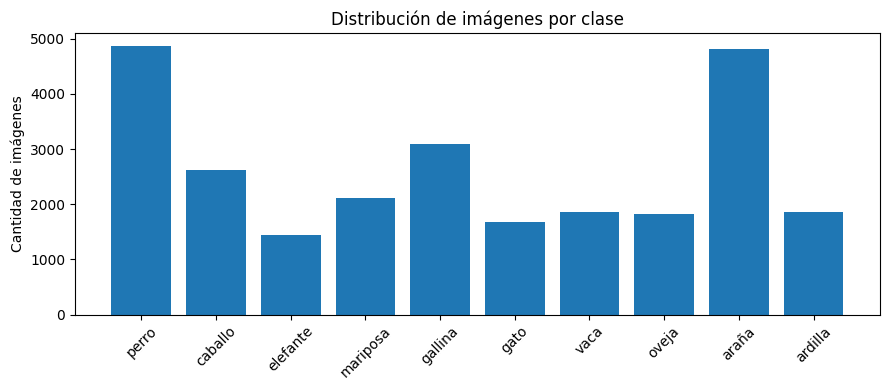

In [4]:
import os
import matplotlib.pyplot as plt

DATA_DIR = "/content/animals10/raw-img"

# Nombres en español para las gráficas y el informe
nombres_es = {
    "cane": "perro", "cavallo": "caballo", "elefante": "elefante",
    "farfalla": "mariposa", "gallina": "gallina", "gatto": "gato",
    "mucca": "vaca", "pecora": "oveja", "scoiattolo": "ardilla",
    "ragno": "araña",
}

clases = sorted(os.listdir(DATA_DIR))
conteo = {c: len(os.listdir(os.path.join(DATA_DIR, c))) for c in clases}

for c in clases:
    print(f"{c:12} ({nombres_es.get(c, '?'):10}): {conteo[c]}")
print("Total:", sum(conteo.values()))

plt.figure(figsize=(9, 4))
plt.bar([nombres_es.get(c, c) for c in clases], conteo.values())
plt.title("Distribución de imágenes por clase")
plt.ylabel("Cantidad de imágenes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [5]:
import numpy as np
from PIL import Image
from sklearn.model_selection import train_test_split

SEED = 42
rutas, etiquetas, corruptas = [], [], []

for i, c in enumerate(clases):
    carpeta = os.path.join(DATA_DIR, c)
    for f in os.listdir(carpeta):
        ruta = os.path.join(carpeta, f)
        try:
            with Image.open(ruta) as img:
                img.verify()
            rutas.append(ruta)
            etiquetas.append(i)
        except Exception:
            corruptas.append(ruta)

rutas, etiquetas = np.array(rutas), np.array(etiquetas)
print("Válidas:", len(rutas), "| Corruptas:", len(corruptas))

# 80% entrenamiento, 20% temporal (estratificado)
X_tr, X_tmp, y_tr, y_tmp = train_test_split(
    rutas, etiquetas, test_size=0.20, stratify=etiquetas, random_state=SEED)

# El 20% se divide a la mitad: 10% validación, 10% prueba
X_val, X_te, y_val, y_te = train_test_split(
    X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)

print("Entrenamiento:", len(X_tr))
print("Validación:   ", len(X_val))
print("Prueba:       ", len(X_te))

Válidas: 26179 | Corruptas: 0
Entrenamiento: 20943
Validación:    2618
Prueba:        2618


In [7]:
import tensorflow as tf

IMG = 128
BATCH = 32
N = len(clases)

def cargar(ruta, etiqueta):
    img = tf.io.read_file(ruta)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG, IMG))
    img = img / 255.0                      # normalización a [0, 1]
    return img, tf.one_hot(etiqueta, N)

augment = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
])

def dataset(X, y, entrenamiento=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    ds = ds.map(cargar, num_parallel_calls=tf.data.AUTOTUNE)
    if entrenamiento:
        ds = ds.shuffle(1000, seed=SEED)
        ds = ds.map(lambda x, y: (augment(x, training=True), y),
                    num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds = dataset(X_tr, y_tr, entrenamiento=True)
val_ds   = dataset(X_val, y_val)
test_ds  = dataset(X_te, y_te)

In [8]:
for imgs, labs in train_ds.take(1):
    print("Forma de imágenes:", imgs.shape)   # esperado: (32, 128, 128, 3)
    print("Forma de etiquetas:", labs.shape)  # esperado: (32, 10)
    print("Valor mínimo:", float(tf.reduce_min(imgs)))
    print("Valor máximo:", float(tf.reduce_max(imgs)))  # esperado: entre 0 y 1

Forma de imágenes: (32, 128, 128, 3)
Forma de etiquetas: (32, 10)
Valor mínimo: 0.0
Valor máximo: 1.0


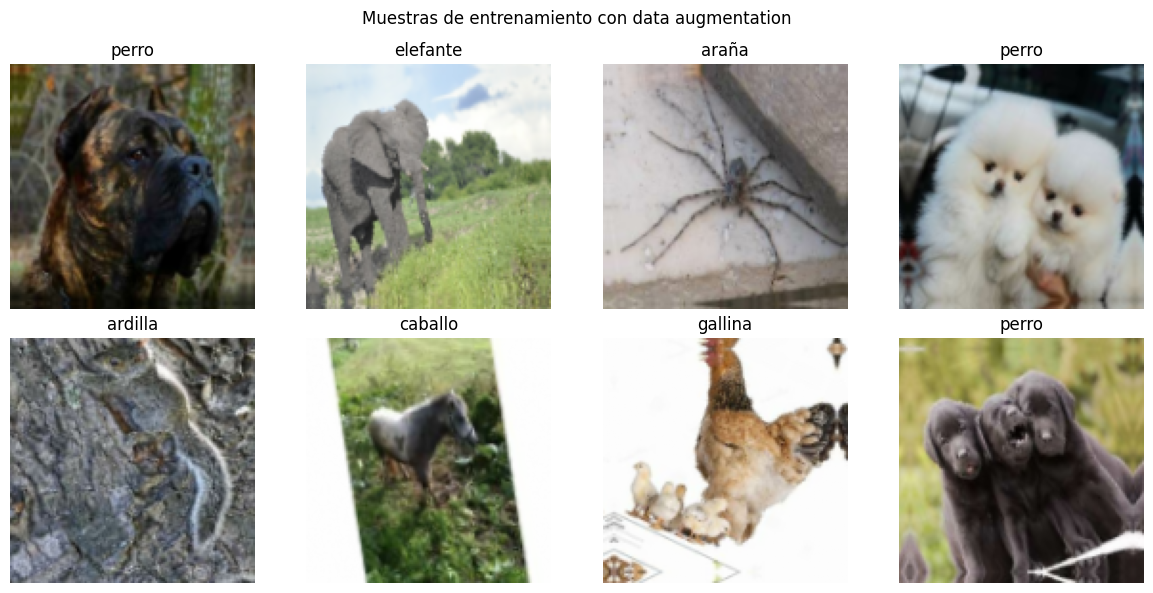

In [9]:
import matplotlib.pyplot as plt

imgs, labs = next(iter(train_ds))
plt.figure(figsize=(12, 6))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(imgs[i])
    plt.title(nombres_es.get(clases[int(tf.argmax(labs[i]))], "?"))
    plt.axis("off")
plt.suptitle("Muestras de entrenamiento con data augmentation")
plt.tight_layout()
plt.show()

In [10]:
import pandas as pd

def guardar(X, y, nombre):
    pd.DataFrame({"ruta": X, "etiqueta": y}).to_csv(
        f"/content/drive/MyDrive/practica2/{nombre}.csv", index=False)

guardar(X_tr, y_tr, "train")
guardar(X_val, y_val, "val")
guardar(X_te, y_te, "test")